# Q3 · 哪些噪聲資訊對 MWPM 最重要？

這本 Notebook 依序整理四項實驗，每節都有方法、可執行程式和已完成的結果。

1. **固定邊際率**。只改 decoder 對 X、Z 一起發生的假設。
2. **Exact ML**。解釋為什麼在 \(d=3\) 把 \(p_Y\) 估低，有時反而更準。
3. **三方向敏感度**。等幅比較強度、X/Z 邊際偏置和相關性。
4. **Darmawan Figure 7 對照**。將 16 個擾動投影成 5 組 Pauli prior。

**閱讀方式**。圖片已嵌入，直接開啟即可閱讀。要執行程式，請在 Notebook 的 Python 環境安裝 numpy、scipy、stim、pymatching（2.3 以上）和 matplotlib。預設會重算快速的 exact ML；將設定中的 `RUN_SIMULATIONS` 改成 `True`，即可重跑模擬。將 `SHOTS` 設為 1,000,000 可對照圖中的正式實驗。Notebook 包含所需函式及圖片，也可在專案資料夾外使用。


In [ ]:
import itertools
from math import exp, expm1, log, sqrt

import numpy as np
import pymatching
import stim
from scipy.stats import beta

RUN_SIMULATIONS = False
SHOTS = 100_000
SEED = 42
TRUE_PRIOR = (0.001, 0.010, 0.001)
EQUAL_PAULI_PRIOR = (0.004, 0.004, 0.004)
QX = QZ = 0.011
INDEPENDENT_PRIOR = (QX * (1 - QZ), QX * QZ, (1 - QX) * QZ)


## 1. 固定邊際率，只改相關性

\(Y\) 同時帶有 \(X\) 和 \(Z\) 分量。掃描 decoder prior 的 \(\hat p_Y\) 時，固定 \(q_X=p_X+p_Y\)、\(q_Z=p_Z+p_Y\)。真實噪聲採用簡報例子 \((0.10\%,1.00\%,0.10\%)\)。

以下共用程式先建立理想量測電路，再在資料 qubit 加一層 Pauli 噪聲。以每顆 qubit 的 \(X/Z\) 偵測事件建 DEM，保留 \(Y\) 的共同來源。Standard MWPM 用邊際模型，correlated MWPM 用聯合模型。兩者共用同一批樣本。


In [ ]:
def memory_circuit(basis, distance, noise):
    """Insert one noise layer between two ideal stabilizer rounds."""
    ideal = stim.Circuit.generated(
        f"surface_code:rotated_memory_{basis}", distance=distance, rounds=2
    ).flattened()
    data = [
        target.value
        for instruction in ideal
        if instruction.name in ("M", "MX")
        for target in instruction.targets_copy()
    ]
    first_reset = next(i for i, gate in enumerate(ideal) if gate.name == "MR")
    if len(data) != distance**2 or len(set(data)) != len(data):
        raise ValueError("Unexpected data qubits in generated circuit")
    return ideal[: first_reset + 1] + noise(data) + ideal[first_reset + 1 :]


def pauli_noise(data):
    circuit = stim.Circuit()
    circuit.append("PAULI_CHANNEL_1", data, TRUE_PRIOR)
    return circuit


def independent_rates(prior):
    """Represent this Pauli channel exactly with independent Pauli flips."""
    px, py, pz = prior
    x_parity = 1 - 2 * (px + py)
    y_parity = 1 - 2 * (px + pz)
    z_parity = 1 - 2 * (py + pz)
    return (
        (1 - sqrt(x_parity * y_parity / z_parity)) / 2,
        (1 - sqrt(x_parity * z_parity / y_parity)) / 2,
        (1 - sqrt(y_parity * z_parity / x_parity)) / 2,
    )


def fault_signatures(basis, distance):
    """Extract each data-qubit Pauli component's detector and observable flips."""
    signatures = []
    for index in range(distance**2):
        components = []
        for gate in ("X_ERROR", "Z_ERROR"):
            def single_fault(data):
                circuit = stim.Circuit()
                circuit.append(gate, [data[index]], 0.125)
                return circuit

            dem = memory_circuit(basis, distance, single_fault).detector_error_model()
            error, = (term for term in dem if term.type == "error")
            components.append(error.targets_copy())
        signatures.append(components)
    return signatures


def decoder_model(ideal_detectors, signatures, prior):
    dem = ideal_detectors.copy()
    rx, ry, rz = independent_rates(prior)
    for x_targets, z_targets in signatures:
        if rx > 1e-15:
            dem.append("error", rx, x_targets)
        if rz > 1e-15:
            dem.append("error", rz, z_targets)
        if ry > 1e-15:
            joint = x_targets + [stim.target_separator()] + z_targets
            dem.append("error", ry, joint)
    return dem


def edge_weights(decoder):
    return {
        tuple(sorted((u, v))) if v is not None else (u, None): attrs["weight"]
        for u, v, attrs in decoder.edges()
    }


def paired_stats(true_failed, other_failed):
    shots = len(true_failed)
    only_true = int((true_failed & ~other_failed).sum())
    only_other = int((other_failed & ~true_failed).sum())
    difference = (only_other - only_true) / shots
    interval = None
    if shots > 1 and only_true + only_other >= 30:
        variance = (only_true + only_other) / shots - difference**2
        margin = 1.96 * sqrt(variance / (shots - 1))
        interval = [difference - margin, difference + margin]
    elif only_true + only_other == 0:
        # With zero discordances, bound their total probability exactly.
        bound = 1 - 0.05 ** (1 / shots)
        interval = [-bound, bound]
    return {
        "only_true_prior_failed": only_true,
        "only_comparison_prior_failed": only_other,
        "ler_difference": difference,
        "95_percent_ci": interval,
    }


In [ ]:
def run_correlation_sweep(shots, seed, basis, distance, sweep=False):
    physical = memory_circuit(basis, distance, pauli_noise)
    detectors, actual = physical.compile_detector_sampler(seed=seed).sample(
        shots, separate_observables=True
    )
    ideal_dem = memory_circuit(
        basis, distance, lambda data: stim.Circuit()
    ).detector_error_model()
    signatures = fault_signatures(basis, distance)
    results, failures, standard_weights, standard_predictions = {}, {}, {}, {}
    correlated_weights = {}
    for name, prior in (("true", TRUE_PRIOR), ("independent", INDEPENDENT_PRIOR)):
        joint_dem = decoder_model(ideal_dem, signatures, prior)
        px, py, pz = prior
        qx, qz = px + py, py + pz
        marginal_prior = (qx * (1 - qz), qx * qz, (1 - qx) * qz)
        # Build standard matching directly from the marginal mechanisms.
        marginal_dem = decoder_model(ideal_dem, signatures, marginal_prior)
        for mode, correlated in (("standard", False), ("correlated", True)):
            decoder = pymatching.Matching.from_detector_error_model(
                joint_dem if correlated else marginal_dem, enable_correlations=correlated
            )
            predicted = decoder.decode_batch(detectors, enable_correlations=correlated)
            key = f"{mode}_{name}"
            failures[key] = np.any(predicted != actual, axis=1)
            results[key] = {
                "failures": int(failures[key].sum()),
                "ler": float(failures[key].mean()),
            }
            if not correlated:
                standard_weights[name] = edge_weights(decoder)
                standard_predictions[name] = predicted
            else:
                correlated_weights[name] = edge_weights(decoder)

    true_weights = standard_weights["true"]
    independent_weights = standard_weights["independent"]
    same_edges = true_weights.keys() == independent_weights.keys()
    max_gap = max(
        (abs(true_weights[edge] - independent_weights[edge]) for edge in true_weights),
        default=0.0,
    ) if same_edges else None
    disagreement = int(np.any(
        standard_predictions["true"] != standard_predictions["independent"], axis=1
    ).sum())
    # Equal-cost paths can be resolved differently when floating-point weights differ.
    if not same_edges or max_gap > 1e-10:
        raise RuntimeError("Standard MWPM does not have matched edge weights")
    correlated_true = correlated_weights["true"]
    correlated_independent = correlated_weights["independent"]
    if correlated_true.keys() != correlated_independent.keys():
        raise RuntimeError("Correlated MWPM does not have matched edge sets")
    correlated_gap = max(
        abs(weight - correlated_independent[edge])
        for edge, weight in correlated_true.items()
    )
    if correlated_gap > 1e-10:
        raise RuntimeError("Correlated MWPM does not have matched initial edge weights")

    true_failed = failures["correlated_true"]
    independent_failed = failures["correlated_independent"]
    only_true = int((true_failed & ~independent_failed).sum())
    only_independent = int((independent_failed & ~true_failed).sum())
    paired_difference = (only_independent - only_true) / shots
    interval = None
    if shots > 1 and only_true + only_independent >= 30:
        variance = ((only_true + only_independent) / shots - paired_difference**2)
        margin = 1.96 * sqrt(variance / (shots - 1))
        interval = [paired_difference - margin, paired_difference + margin]
    result = {
        "distance": distance,
        "basis": basis,
        "shots": shots,
        "seed": seed,
        "stim": stim.__version__,
        "pymatching": pymatching.__version__,
        "results": results,
        "standard_check": {
            "same_edges": same_edges,
            "max_absolute_weight_gap": max_gap,
            "prediction_disagreements": disagreement,
        },
        "correlated_paired": {
            "max_initial_edge_weight_gap": correlated_gap,
            "only_true_prior_failed": only_true,
            "only_independent_prior_failed": only_independent,
            "ler_independent_minus_true": paired_difference,
            "approximate_95_percent_ci": interval,
        },
    }
    if sweep:
        rows = []
        for py in (QX * QZ, 0.0025, 0.005, 0.0075, TRUE_PRIOR[1], 0.0105):
            prior = (QX - py, py, QZ - py)
            dem = decoder_model(ideal_dem, signatures, prior)
            decoder = pymatching.Matching.from_detector_error_model(dem, enable_correlations=True)
            weights = edge_weights(decoder)
            if weights.keys() != correlated_true.keys():
                raise RuntimeError(f"Initial edge set mismatch at p_Y={py}")
            gap = max(abs(weights[edge] - weight) for edge, weight in correlated_true.items())
            if gap > 1e-10:
                raise RuntimeError(f"Initial edge weight mismatch at p_Y={py}")
            predicted = decoder.decode_batch(detectors, enable_correlations=True)
            failed = np.any(predicted != actual, axis=1)
            rows.append({
                "prior_py": py,
                "failures": int(failed.sum()),
                "ler": float(failed.mean()),
                "max_initial_edge_weight_gap": gap,
                **paired_stats(true_failed, failed),
            })
        result["correlation_sweep"] = rows
    return result


In [ ]:
correlation_runs = {}
if RUN_SIMULATIONS:
    for distance in (3, 5):
        for basis in ("z", "x"):
            result = run_correlation_sweep(SHOTS, SEED, basis, distance, sweep=True)
            correlation_runs[distance, basis] = result
            print(f"d={distance}, {basis.upper()}-memory")
            for row in result["correlation_sweep"]:
                print(f"  prior pY={row['prior_py']:.4%}  LER={row['ler']:.4%}")


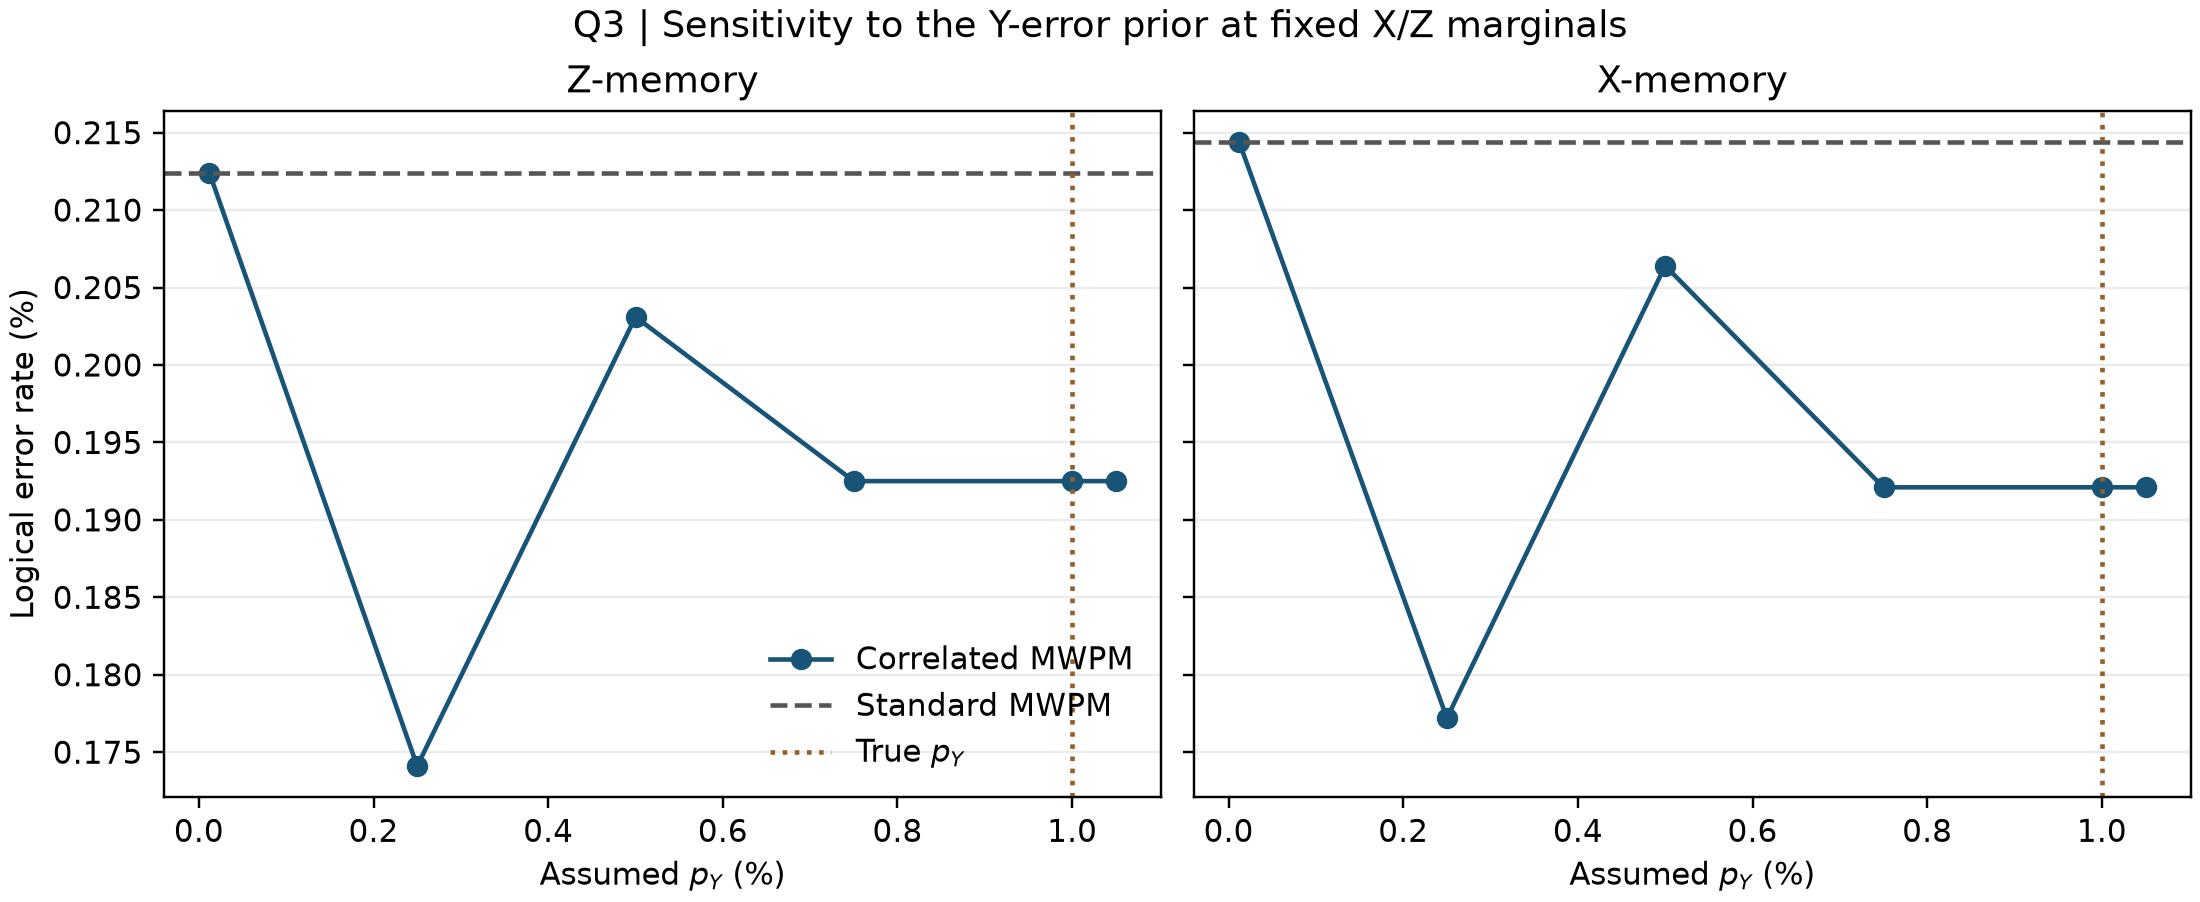

*d=3 的六點掃描。灰線是 standard MWPM，棕色直線是真實 pY。*


**已完成的結果。** 在強 Y 偏置下，d=3 的六個測試點以 0.25% prior 最低，d=5 的最低觀察值出現在 0.75%。d=5 若將相關性完全忽略，Z-memory 的 LER 由 0.0163% 升到 0.0349%，X-memory 由 0.0164% 升到 0.0357%。正式結果每個基底、碼距各使用 100 萬 shots。


## 2. 用 exact ML 看出差異來自哪裡

在 \(d=3\)，枚舉 \(4^9=262{,}144\) 種錯誤型態。對每一種 syndrome，把導致 logical flip 和沒有導致 logical flip 的機率分別加總，選機率較大的答案。

兩個 correlated prior 在 47 種 syndrome 上做出不同決策。0.25% prior 雖只在 17 種與 exact ML 一致，但那些 syndrome 對總錯誤率的影響更大。這解釋了它在這組實驗裡為什麼能勝過真實 prior。


In [ ]:
def signature_mask(targets, num_detectors):
    mask = 0
    for target in targets:
        if target.is_relative_detector_id():
            mask ^= 1 << target.val
        elif target.is_logical_observable_id() and target.val == 0:
            mask ^= 1 << num_detectors
        else:
            raise ValueError(f"Unsupported fault target: {target}")
    return mask


def exact_joint_distribution(signatures, num_detectors, prior=TRUE_PRIOR):
    """Enumerate all Pauli patterns, then group by detector mask and logical flip."""
    pattern_masks = np.array([0], dtype=np.int64)
    probabilities = np.array([1.0])
    pauli_probabilities = np.array([1 - sum(prior), *prior])
    for x_targets, z_targets in signatures:
        x = signature_mask(x_targets, num_detectors)
        z = signature_mask(z_targets, num_detectors)
        pattern_masks = (pattern_masks[:, None] ^ [0, x, x ^ z, z]).ravel()
        probabilities = (probabilities[:, None] * pauli_probabilities).ravel()
    joint = np.bincount(pattern_masks, weights=probabilities, minlength=2 << num_detectors)
    if not np.isclose(joint.sum(), 1, rtol=0, atol=1e-12):
        raise RuntimeError("Pauli pattern probabilities do not sum to one")
    return joint.reshape(2, -1).T


def analyze_exact_ml(basis):
    distance = 3
    ideal = memory_circuit(basis, distance, lambda _: stim.Circuit()).detector_error_model()
    signatures = fault_signatures(basis, distance)
    joint = exact_joint_distribution(signatures, ideal.num_detectors)
    masks = np.flatnonzero(joint.sum(axis=1))
    joint = joint[masks]
    dets = ((masks[:, None] >> np.arange(ideal.num_detectors)) & 1).astype(np.uint8)
    ml = joint.argmax(axis=1)
    predictions = {}
    errors = {}
    for name, py in (("low", 0.0025), ("true", TRUE_PRIOR[1])):
        prior = (QX - py, py, QZ - py)
        dem = decoder_model(ideal, signatures, prior)
        decoder = pymatching.Matching.from_detector_error_model(dem, enable_correlations=True)
        predictions[name] = decoder.decode_batch(dets, enable_correlations=True)[:, 0]
        errors[name] = joint[np.arange(len(masks)), 1 - predictions[name]]

    delta = errors["true"] - errors["low"]
    ml_error = joint.min(axis=1)
    if any(np.any(error < ml_error) for error in errors.values()):
        raise RuntimeError("A matching prediction beat exact ML on a syndrome")
    disagreement = np.flatnonzero(predictions["low"] != predictions["true"])
    tolerance = 1e-14
    low_wins = delta > tolerance
    true_wins = delta < -tolerance
    rows = [
        {
            "detectors": np.flatnonzero(dets[i]).tolist(),
            "syndrome_probability": float(joint[i].sum()),
            "logical_one_given_syndrome": float(joint[i, 1] / joint[i].sum()),
            "ml_flip": None if abs(joint[i, 0] - joint[i, 1]) <= tolerance else int(ml[i]),
            "low_prior_flip": int(predictions["low"][i]),
            "true_prior_flip": int(predictions["true"][i]),
            "true_minus_low_ler_contribution": float(delta[i]),
        }
        for i in sorted(disagreement, key=lambda i: abs(delta[i]), reverse=True)
    ]
    return {
        "basis": basis,
        "patterns": 4**(distance**2),
        "reachable_syndromes": len(masks),
        "exact_ler": {
            "ml": float(ml_error.sum()),
            "low_prior": float(errors["low"].sum()),
            "true_prior": float(errors["true"].sum()),
        },
        "differing_syndromes": len(rows),
        "low_prior_ml_matches_among_disagreements": int(low_wins.sum()),
        "true_prior_ml_matches_among_disagreements": int(true_wins.sum()),
        "ml_ties_among_disagreements": int(len(rows) - low_wins.sum() - true_wins.sum()),
        "low_prior_ler_gain_on_its_wins": float(delta[low_wins].sum()),
        "true_prior_ler_gain_on_its_wins": float(-delta[true_wins].sum()),
        "syndrome_details": rows,
    }


In [ ]:
exact_results = [analyze_exact_ml(basis) for basis in ("z", "x")]
for result in exact_results:
    ler = result["exact_ler"]
    print(f"{result['basis'].upper()}-memory  ML={ler['ml']:.5%}  "
          f"0.25% prior={ler['low_prior']:.5%}  matched={ler['true_prior']:.5%}")
    print("影響最大的 syndrome：", result["syndrome_details"][0])


## 3. 哪個噪聲參數最敏感？

比較兩組真實噪聲，兩者總 Pauli 錯誤率均為 1.2%。

- 強 \(Y\) 偏置 \((p_X,p_Y,p_Z)=(0.10\%,1.00\%,0.10\%)\)
- 等 Pauli 機率 \((p_X,p_Y,p_Z)=(0.40\%,0.40\%,0.40\%)\)

每次只改一個 prior 座標：總邊際強度 \(q_X+q_Z\)、邊際偏置 \((q_X-q_Z)/(q_X+q_Z)\)，或聯合分布的 log odds ratio。用總變差距離（TV）對齊擾動幅度。\(d=3\) 用精確枚舉，\(d=5\) 用配對模擬。三方向比較以各 decoder 的真實 prior LER 為基準。


In [ ]:
def pauli_prior(strength, bias, log_odds_ratio):
    qx = strength * (1 + bias) / 2
    qz = strength * (1 - bias) / 2
    odds_ratio = exp(log_odds_ratio)
    b = 1 + (odds_ratio - 1) * (qx + qz)
    c = odds_ratio * qx * qz
    py = 2 * c / (b + sqrt(b * b - 4 * (odds_ratio - 1) * c))
    return np.array([1 - qx - qz + py, qx - py, py, qz - py])


def matched_tv_priors(levels, true_prior):
    px, py, pz = true_prior
    qx, qz = px + py, pz + py
    log_odds_ratio = log((1 - px - py - pz) * py / (px * pz))
    center = np.array([qx + qz, (qx - qz) / (qx + qz), log_odds_ratio])
    baseline = pauli_prior(*center)
    np.testing.assert_allclose(baseline[1:], true_prior, atol=1e-15)
    # Search each coordinate separately while keeping the other two fixed.
    for level in levels:
        for index, name in enumerate(PARAMETERS):
            broad = level > 0.002
            signs = (-1,) if broad and name != "bias" else (-1, 1)
            for sign in signs:
                def prior_at(step):
                    coordinates = center.copy()
                    coordinates[index] += sign * step
                    prior = pauli_prior(*coordinates)
                    return coordinates, prior, float(abs(baseline - prior).sum() / 2)

                low, high = 0.0, (0.999 * center[0], 0.999, 30.0)[index]
                if prior_at(high)[2] < level:
                    raise ValueError(f"Cannot bracket TV={level} for {name}")
                for _ in range(55):
                    mid = (low + high) / 2
                    if prior_at(mid)[2] < level:
                        low = mid
                    else:
                        high = mid
                coordinates, prior, tv = prior_at(high)
                if np.any(prior < 0) or not np.isclose(tv, level, atol=1e-14):
                    raise ValueError(f"Infeasible TV={level} for {name}")
                yield name, sign, coordinates.tolist(), prior.tolist(), tv


def make_decoder(ideal, signatures, prior, correlated):
    if not correlated:
        px, py, pz = prior
        qx, qz = px + py, py + pz
        prior = (qx * (1 - qz), qx * qz, (1 - qx) * qz)
    dem = decoder_model(ideal, signatures, prior)
    return pymatching.Matching.from_detector_error_model(dem, enable_correlations=correlated)


def paired_interval(reference_failed, failed):
    stats = paired_stats(reference_failed, failed)
    worse = stats["only_comparison_prior_failed"]
    better = stats["only_true_prior_failed"]
    if worse + better:
        # Bonferroni-combine two exact binomial intervals for the discordant rates.
        n = len(failed)
        tail = 0.05 / 4

        def bounds(count):
            return (
                beta.ppf(tail, count, n - count + 1) if count else 0.0,
                beta.ppf(1 - tail, count + 1, n - count) if count < n else 1.0,
            )

        worse_low, worse_high = bounds(worse)
        better_low, better_high = bounds(better)
        stats["95_percent_ci"] = [worse_low - better_high, worse_high - better_low]
    return stats


def analyze_sensitivity(distance, basis, shots, seed, priors, true_prior):
    ideal = memory_circuit(basis, distance, lambda _: stim.Circuit()).detector_error_model()
    signatures = fault_signatures(basis, distance)
    if distance == 3:
        joint = exact_joint_distribution(signatures, ideal.num_detectors, true_prior)
        masks = np.flatnonzero(joint.sum(axis=1))
        joint = joint[masks]
        dets = ((masks[:, None] >> np.arange(ideal.num_detectors)) & 1).astype(np.uint8)
    else:
        def noise(data):
            circuit = stim.Circuit()
            circuit.append("PAULI_CHANNEL_1", data, true_prior)
            return circuit

        circuit = memory_circuit(basis, distance, noise)
        dets, actual = circuit.compile_detector_sampler(seed=seed).sample(
            shots, separate_observables=True
        )

    rows, baselines = [], {}
    for mode, correlated in (("standard", False), ("correlated", True)):
        decoder = make_decoder(ideal, signatures, true_prior, correlated)
        reference = decoder.decode_batch(dets, enable_correlations=correlated)[:, 0]
        reference_weights = edge_weights(decoder)
        if distance == 3:
            positions = np.arange(len(reference))
            baseline = float(joint[positions, 1 - reference].sum())
        else:
            reference_failed = reference != actual[:, 0]
            baseline = float(reference_failed.mean())
        baselines[mode] = baseline

        for name, sign, coords, prior, tv in priors:
            decoder = make_decoder(ideal, signatures, prior[1:], correlated)
            predicted = decoder.decode_batch(dets, enable_correlations=correlated)[:, 0]
            if name in ("correlation", "independence"):
                weights = edge_weights(decoder)
                if weights.keys() != reference_weights.keys() or any(
                    abs(weights[edge] - weight) > 1e-10
                    for edge, weight in reference_weights.items()
                ):
                    raise RuntimeError("Correlation perturbation changed initial weights")
            if distance == 3:
                ler = float(joint[positions, 1 - predicted].sum())
                stats = {"ler_difference": ler - baseline}
            else:
                failed = predicted != actual[:, 0]
                ler = float(failed.mean())
                stats = paired_interval(reference_failed, failed)
            rows.append({
                "decoder": mode, "parameter": name, "direction": sign, "tv": tv,
                "strength_bias_log_odds_ratio": coords, "prior_i_x_y_z": prior, "ler": ler,
                "prediction_disagreements": int(np.count_nonzero(predicted != reference)),
                **stats,
            })
    return {
        "distance": distance, "basis": basis,
        "method": "exact enumeration" if distance == 3 else "paired simulation",
        "shots": None if distance == 3 else shots, "matched_baselines": baselines,
        "exact_ml_ler": float(joint.min(axis=1).sum()) if distance == 3 else None,
        "rows": rows,
    }


def plot_sensitivity(results, output, tv):
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt

    fig, axes = plt.subplots(2, 2, figsize=(10, 6.3), layout="constrained", sharex=True)
    for ax, result in zip(axes.flat, results):
        ax.axhline(0, color="0.55", linewidth=0.8)
        for center, mode, color, marker in (
            (-0.1, "standard", "#1b6580", "o"),
            (0.1, "correlated", "#a5582c", "s"),
        ):
            rows = [r for r in result["rows"] if r["decoder"] == mode]
            for index, parameter in enumerate(PARAMETERS):
                selected = [
                    r for r in rows if r["parameter"] == parameter and np.isclose(r["tv"], tv)
                ]
                for row in selected:
                    x = index + center + row["direction"] * 0.035
                    y = row["ler_difference"] * 100
                    interval = row.get("95_percent_ci")
                    if interval is not None:
                        ax.vlines(x, interval[0]*100, interval[1]*100, color=color, alpha=0.55)
                    ax.scatter(x, y, marker=marker, color=color, s=25,
                               label=mode.capitalize() if index == 0 and row["direction"] == -1 else None)
        ax.set_title(f"d={result['distance']} · {result['basis'].upper()}-memory")
        ax.set_xticks(range(len(PARAMETERS)), ["Strength", "X/Z bias", "X–Z correlation"])
        ax.grid(axis="y", alpha=0.18)
    for ax in axes[:, 0]:
        ax.set_ylabel("LER change (percentage points)")
    axes[0, 0].legend(frameon=False)
    fig.suptitle(f"Q3 | Prior sensitivity at equal total variation (TV = {tv:.1%})")
    fig.supxlabel("Left/right offsets show negative/positive perturbations within each decoder")
    fig.savefig(output, dpi=200)


In [ ]:
PARAMETERS = ("strength", "bias", "correlation")
sensitivity_runs = {}

if RUN_SIMULATIONS:
    models = (
        ("strong_y", TRUE_PRIOR, (0.0005, 0.0009, 0.005, 0.01)),
        ("equal_pauli", EQUAL_PAULI_PRIOR, (0.0005, 0.0009, 0.005)),
    )
    for name, prior, tv_levels in models:
        priors = list(matched_tv_priors(tv_levels, prior))
        if name == "equal_pauli":
            px, py, pz = prior
            qx, qz = px + py, pz + py
            coords = [qx + qz, (qx - qz) / (qx + qz), 0]
            independent = pauli_prior(*coords)
            priors.append(("independence", -1, coords, independent.tolist(), 2 * abs(py - qx * qz)))
        results = [
            analyze_sensitivity(distance, basis, SHOTS, SEED, priors, prior)
            for distance in (3, 5) for basis in ("z", "x")
        ]
        sensitivity_runs[name] = results
        print(name, [r["matched_baselines"] for r in results])


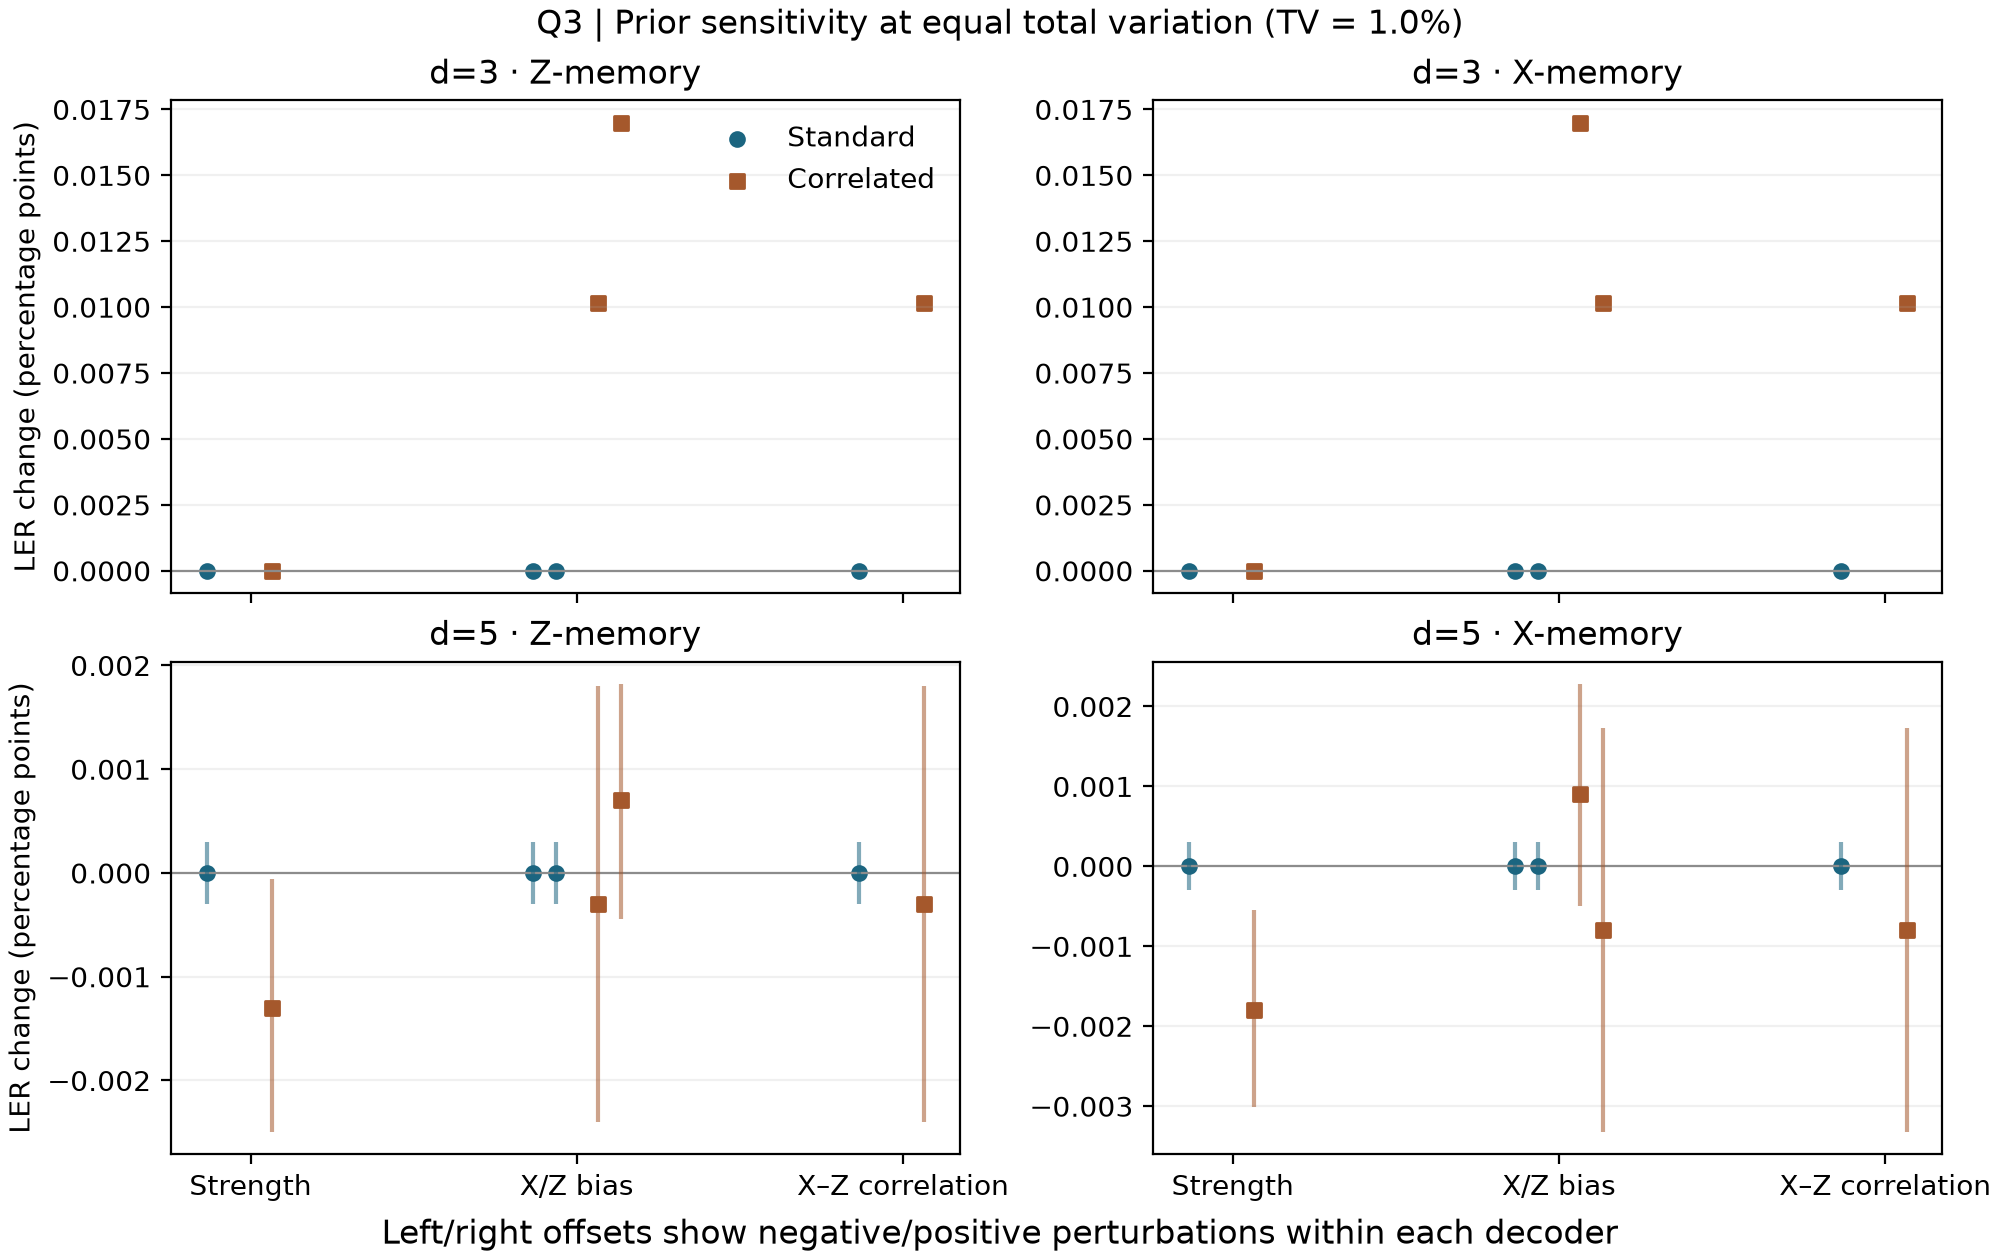

*強 Y 偏置，TV = 1.0%。d=3 中偏置增加 LER 最多；d=5 未重現相同排序。*


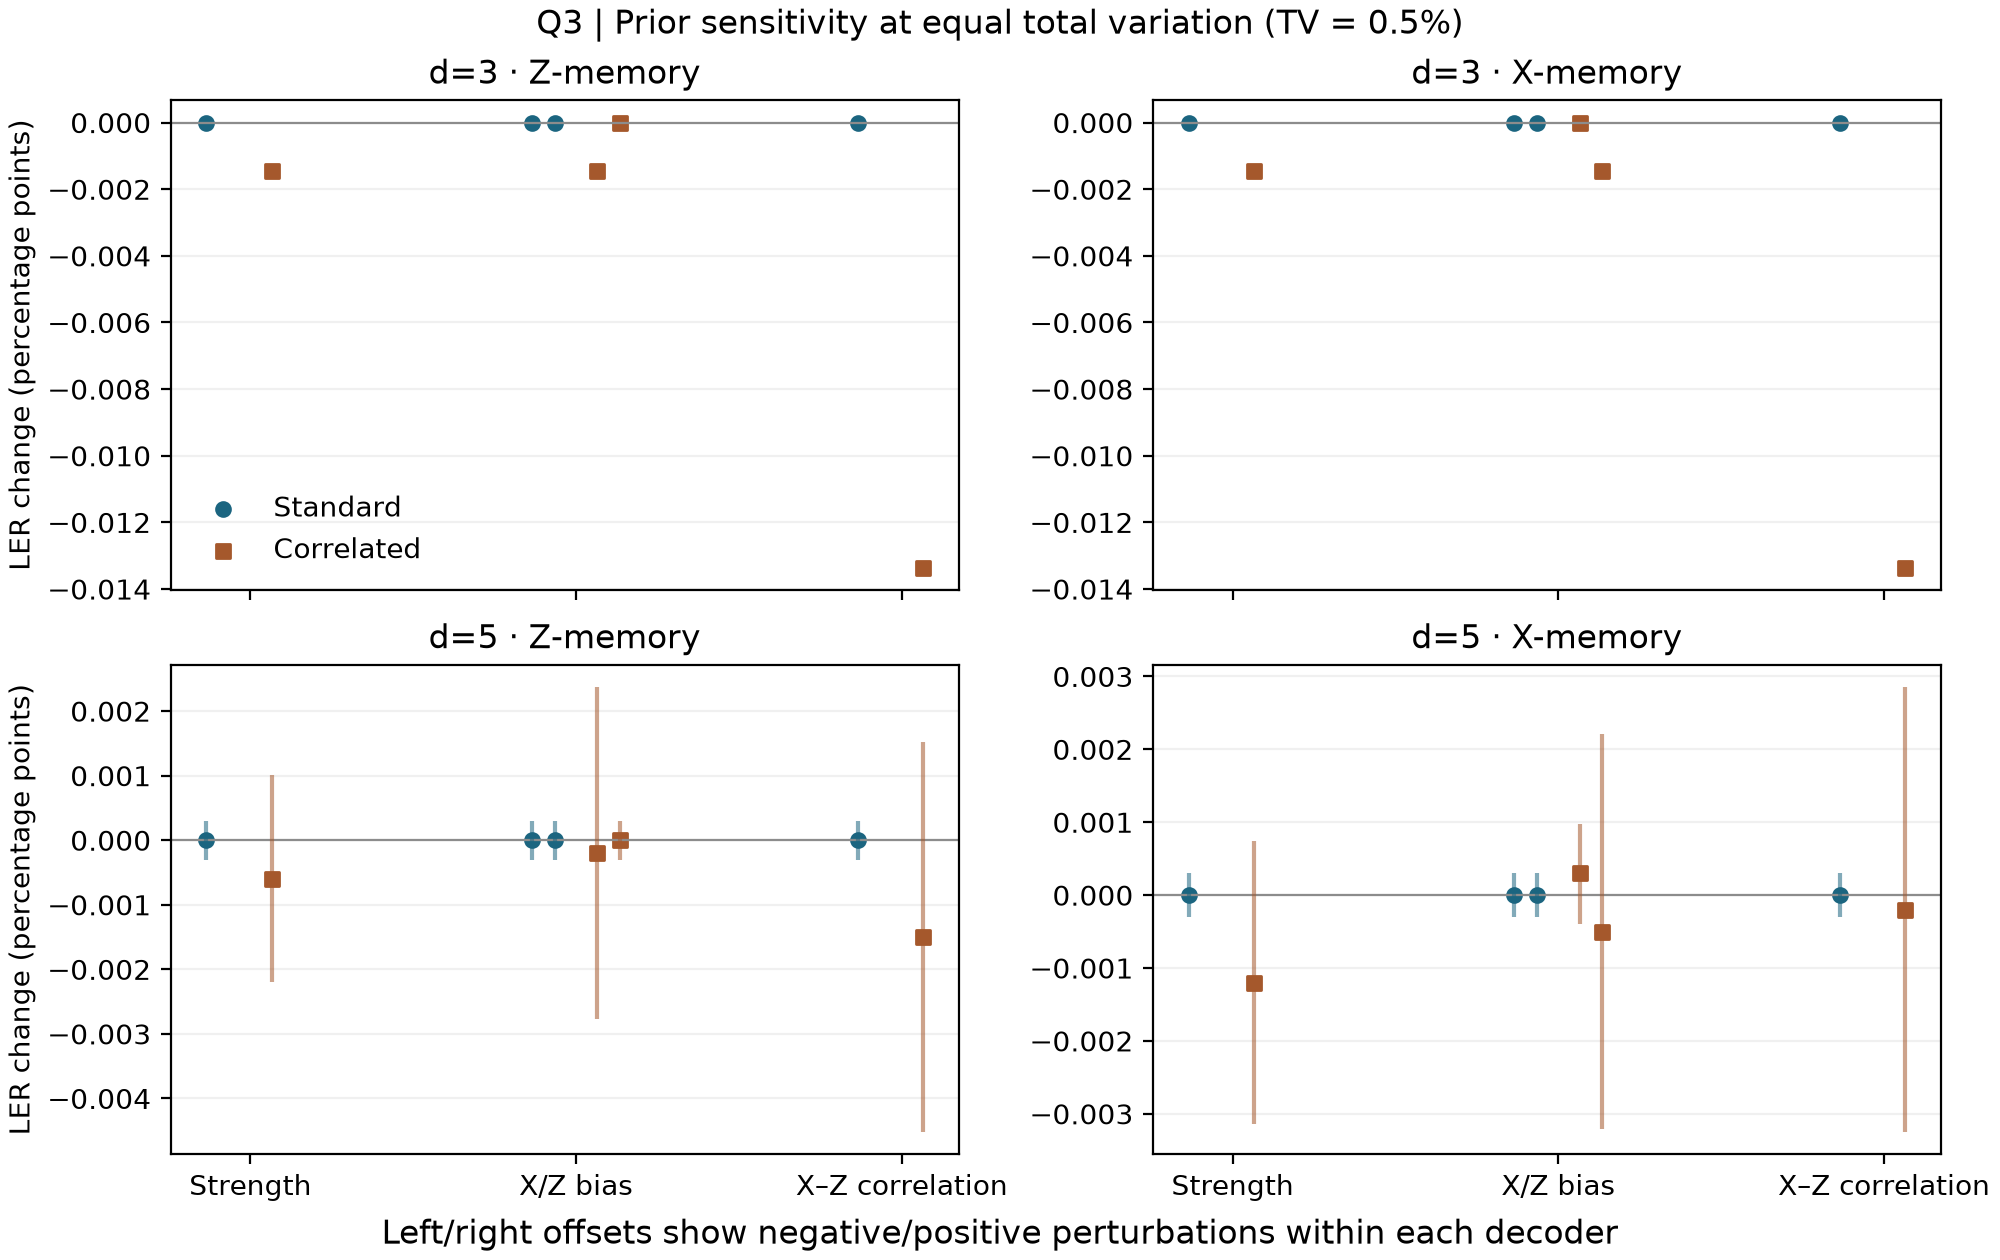

*等 Pauli 機率，TV = 0.5%。在 d=3，調低相關性對 LER 的影響最大。*


**共同幅度比較。** 兩組都測了 TV = 0.5%。強 Y 偏置組在 d=3 的三方向均未改變預測；等 Pauli 機率組在 d=3 調低相關性時，LER 從 0.11901% 降到 0.10566%。後者在 d=5 的相關性效果仍需更多資料確認。兩張圖的展示幅度各自標在標題。


## 4. Darmawan Figure 7 的 Pauli 投影

把真實 APD 通道與 \(\chi_i=I_4+P_i\) 的擾動投影到 Pauli 機率。用 \(\delta=0.25\) 加入擾動後再正規化。16 個標籤在投影後對應 5 組不同 prior。用同一批真實資料分別計算 standard 和 correlated MWPM 的 LER 差值。

文獻對應條件為 \(d=7,T_1=T_2=10.88\) 與 \(d=9,T_1=T_2=16.32\)。每個條件做 X/Z-memory。此處採 Pauli 投影與 LER，原論文採完整 APD 與 logical channel 的 diamond distance。 [原論文 Figure 7](https://arxiv.org/html/2403.08706#S3.SS4)


In [ ]:
LABELS = tuple(a + b for a, b in itertools.product("IXYZ", repeat=2))
FIGURE_CASES = ((7, 10.88), (9, 16.32))
PAULI_DIAGONALS = {
    "II": (2, 2, 2, 2), "IZ": (2, 0, 2, 0), "ZI": (2, 2, 0, 0),
    "ZZ": (2, 0, 0, 2), "off_diagonal": (1, 1, 1, 1),
}


In [ ]:
def projected_priors(t1, delta):
    # Figure 7 uses T1 = T2 and t = 1, giving equal X, Y and Z probabilities.
    p = -expm1(-1 / t1) / 4
    matched = np.array([1 - 3 * p, p, p, p])
    priors = {"matched": matched}
    for name, diagonal in PAULI_DIAGONALS.items():
        prior = matched + delta * np.array(diagonal)
        priors[name] = prior / prior.sum()
    return priors


def validate_joint_prior(prior):
    """Check that the DEM mechanisms reconstruct the projected Pauli prior."""
    rates = independent_rates(prior[1:])
    if any(not 0 <= rate <= 1 for rate in rates):
        raise ValueError(f"Prior cannot use this independent-mechanism DEM: {prior}")
    reconstructed = np.array([1.0, 0.0, 0.0, 0.0])
    for mask, rate in zip((1, 2, 3), rates):
        reconstructed = (1 - rate) * reconstructed + rate * reconstructed[np.arange(4) ^ mask]
    np.testing.assert_allclose(reconstructed, prior, atol=1e-13, rtol=0)


def difference_ci(worse, better, shots):
    if worse + better == 0:
        bound = 1 - 0.05 ** (1 / shots)
        return [-bound, bound]
    # Two simultaneous exact binomial intervals bound the difference of paired rates.
    def bounds(count):
        tail = 0.05 / 4
        low = beta.ppf(tail, count, shots - count + 1) if count else 0.0
        high = beta.ppf(1 - tail, count + 1, shots - count) if count < shots else 1.0
        return low, high

    worse_low, worse_high = bounds(worse)
    better_low, better_high = bounds(better)
    return [float(worse_low - better_high), float(worse_high - better_low)]


def run_figure7_case(distance, t1, basis, shots, seed, delta):
    priors = projected_priors(t1, delta)
    for prior in priors.values():
        validate_joint_prior(prior)

    def noise(data):
        layer = stim.Circuit()
        layer.append("PAULI_CHANNEL_1", data, priors["matched"][1:])
        return layer

    sampler = memory_circuit(basis, distance, noise).compile_detector_sampler(seed=seed)
    ideal = memory_circuit(basis, distance, lambda _: stim.Circuit()).detector_error_model()
    signatures = fault_signatures(basis, distance)
    decoders = {}
    counts = {}
    for correlated in (False, True):
        decoders[correlated] = {
            name: make_decoder(ideal, signatures, prior[1:], correlated)
            for name, prior in priors.items()
        }
        counts[correlated] = {name: np.zeros(3, dtype=np.int64) for name in priors}

    for start in range(0, shots, 50_000):
        dets, actual = sampler.sample(
            min(50_000, shots - start), separate_observables=True, bit_packed=True
        )
        for correlated, models in decoders.items():
            def failed(decoder):
                prediction = decoder.decode_batch(
                    dets, bit_packed_shots=True, enable_correlations=correlated
                )
                return prediction[:, 0] != actual[:, 0]

            reference = failed(models["matched"])
            counts[correlated]["matched"][0] += reference.sum()
            for name in PAULI_DIAGONALS:
                error = failed(models[name])
                counts[correlated][name] += (
                    error.sum(), (error & ~reference).sum(), (reference & ~error).sum()
                )

    results = {}
    for correlated, group in counts.items():
        mode = "correlated" if correlated else "standard"
        results[mode] = {}
        for name, (failures, worse, better) in group.items():
            assert failures - group["matched"][0] == worse - better
            results[mode][name] = {
                "failures": int(failures), "ler": float(failures / shots),
                "only_perturbed_failed": int(worse), "only_matched_failed": int(better),
                "delta_ler": float((worse - better) / shots),
                "95_percent_ci": difference_ci(worse, better, shots) if name != "matched" else None,
            }
    return {
        "distance": distance, "T1": t1, "T2": t1, "basis": basis, "shots": shots,
        "priors_i_x_y_z": {name: prior.tolist() for name, prior in priors.items()},
        "decoders": results,
    }


def plot_figure7(results, delta, output):
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt

    fig, axes = plt.subplots(2, 2, figsize=(13, 6.8), layout="constrained", sharex=True)
    for ax, result in zip(axes.flat, results):
        positions = np.arange(len(LABELS))
        ax.axhline(0, color="0.45", linewidth=0.8)
        for mode, offset, color in (("standard", -0.18, "#246582"), ("correlated", 0.18, "#ae582d")):
            data = result["decoders"][mode]
            rows = [data[label if label in PAULI_DIAGONALS else "off_diagonal"] for label in LABELS]
            values = np.array([row["delta_ler"] for row in rows]) * 100
            intervals = np.array([row["95_percent_ci"] for row in rows]) * 100
            x = positions + offset
            ax.bar(x, values, width=0.34, color=color, label=mode.capitalize(), alpha=0.84)
            ax.errorbar(x, values, yerr=[values - intervals[:, 0], intervals[:, 1] - values],
                        fmt=".", color=color, markersize=3, capsize=1.8, linewidth=0.8)
        ax.set_title(f"d={result['distance']}, T₁=T₂={result['T1']:.2f} · {result['basis'].upper()}-memory")
        ax.set_xticks(positions, LABELS)
        ax.grid(axis="y", alpha=0.18)
    for ax in axes[:, 0]:
        ax.set_ylabel("ΔLER (percentage points)")
    axes[0, 0].legend(frameon=False)
    fig.supxlabel("Original perturbation label · 16 labels map to 5 distinct Pauli priors")
    fig.suptitle(f"Figure 7 Pauli projection | ΔLER vs. matched MWPM (δ={delta:g}, paired 95% CI)")
    fig.savefig(output, dpi=200)


In [ ]:
figure7_runs = []
if RUN_SIMULATIONS:
    for distance, t1 in FIGURE_CASES:
        for basis in ("z", "x"):
            result = run_figure7_case(distance, t1, basis, SHOTS, SEED, delta=0.25)
            figure7_runs.append(result)
            correlated = result["decoders"]["correlated"]
            print(f"d={distance} {basis.upper()}-memory  "
                  f"matched={correlated['matched']['ler']:.4%}  IZ={correlated['IZ']['ler']:.4%}")


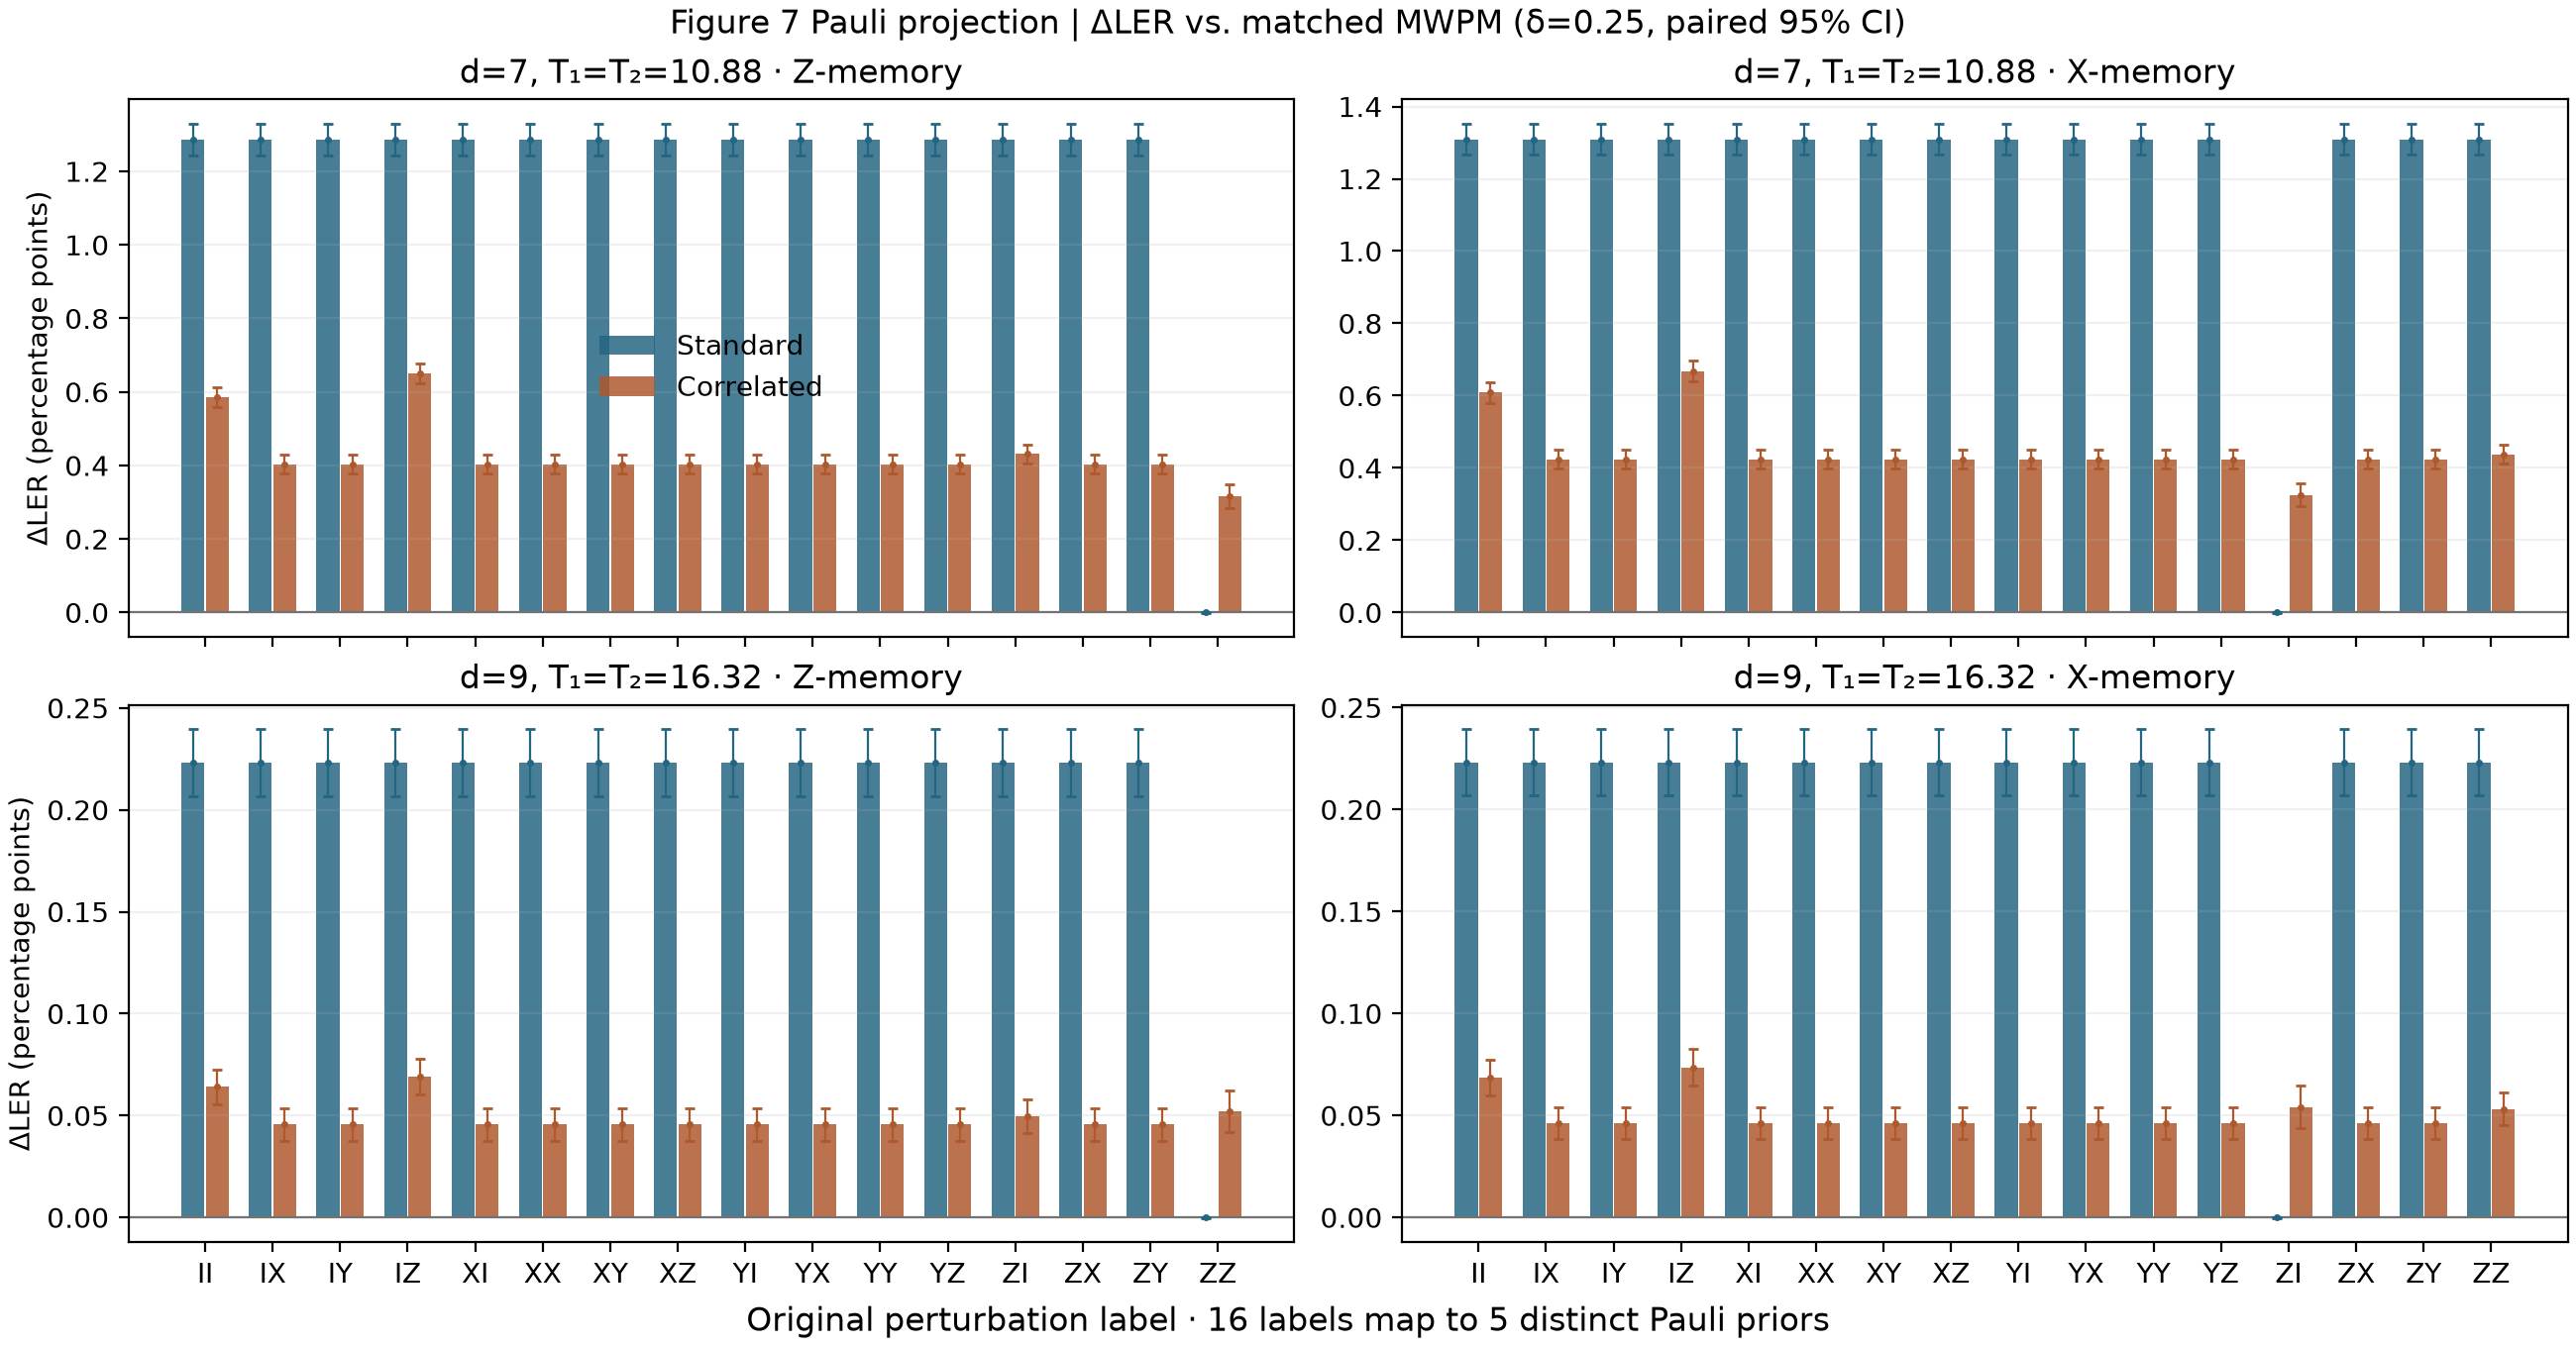

*Figure 7 的 MWPM 對照。每個條件 100 萬 shots。柱高為相對於各自 matched prior 的 LER 差，附配對 95% CI。*


**已完成的結果。** Correlated MWPM 的 IZ 在四種條件下都有最大的觀察 LER 增幅。Standard MWPM 的 IZ 則和其他多個擾動並列。IZ 也改變了兩側的邊際率，解讀相關性本身的效果時，應回到第 1 節的固定邊際對照。


## 總結

- **有沒有提供相關性資訊**。強 Y 偏置、d=5 下影響最大，真實 prior 使 LER 比獨立 prior 低一半以上。
- **相關性要估到多準**。六點掃描中，表現最好的 prior 隨碼距改變。Exact ML 顯示部分 syndrome 對總 LER 特別重要。
- **哪個參數最值得校準**。排序要連同真實噪聲、碼距與擾動幅度解讀。Figure 7 的 IZ 是複合擾動，三方向等 TV 實驗則用來分辨單項影響。

實驗的物理模型為均勻、單層資料 qubit Pauli 噪聲與理想 syndrome 量測。
